# Solutions to the exercises of Chapter 3

Sample solutions for [Chapter 3, Fins and extended surfaces](../../notebooks/part1_conduction/03_fins.ipynb).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_bvp
from scipy.special import i0, i1, k0, k1

try:
    from engtransport import reference
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import reference
from engtransport.plotting import panel_label, use_style

use_style()

## Exercise 1. A thermometer well

The tube is a fin whose base is at the wall temperature and whose tip holds the
thermocouple. Heat enters through its outer surface only, so $P = \pi D$ and
$A_c = \pi(D^2 - d^2)/4$. With $\theta = T - T_{\rm gas}$, Eq. (3.3) gives the tip at
$\theta_{\rm tip} = \theta_b/\cosh mL$: the thermocouple reads low by
$(T_{\rm gas} - T_{\rm wall})/\cosh mL$.

In [2]:
D, d, h_g, L_well = 0.010, 0.007, 30.0, 0.100
T_gas, T_wall = 300.0, 200.0
A_c = math.pi * (D**2 - d**2) / 4
P = math.pi * D
for name, k in (("stainless steel", 16.0), ("carbon steel", 50.0)):
    m = math.sqrt(h_g * P / (k * A_c))
    error = (T_gas - T_wall) / math.cosh(m * L_well)
    L_needed = math.acosh((T_gas - T_wall) / 0.5) / m
    print(f"{name:15s}: m = {m:5.1f} 1/m, mL = {m * L_well:.2f}, reading {error:4.1f} K too low;"
          f" error below 0.5 K needs L > {1e3 * L_needed:.0f} mm")

stainless steel: m =  38.3 1/m, mL = 3.83, reading  4.3 K too low; error below 0.5 K needs L > 156 mm
carbon steel   : m =  21.7 1/m, mL = 2.17, reading 22.6 K too low; error below 0.5 K needs L > 276 mm


The stainless steel well reads 4.3 K low. Because the error falls as $e^{-mL}$, the well
must reach 156 mm into the gas for an error below 0.5 K. Carbon steel is worse, not better:
it conducts the heat of the gas back to the cold wall three times as easily, so the error
is 23 K and the well would need to be 276 mm long. For a thermometer well, a poor
conductor with thin walls is what one wants. In a real duct the cold wall also cools the
tip by radiation, which adds to the error.

## Exercise 2. A thermal break

The block is a plane resistance per metre of facade, $R'_b = L_b/(k_{\rm eq}t)$, in series
with the resistance of the long fin outside it, $1/C'$, where $C'$ is the heat per kelvin
per metre of the slab from Section 3.5:

In [3]:
k_c, t_slab, L_slab, h_out, theta_b = 2.3, 0.180, 1.5, 23.0, 53.0
R_break = 0.080 / (0.20 * t_slab)
C_2d = 2 * reference.plate_fin_2d_series(L_slab, t_slab / 2, k_c, h_out)["Q_per_K"]
C_1d = math.sqrt(2 * h_out * k_c * t_slab)
for name, C in (("2-D slab", C_2d), ("1-D slab", C_1d)):
    q = theta_b / (R_break + 1 / C)
    print(f"{name}: R'_break = {R_break:.2f} m K/W, R'_fin = {1 / C:.3f} m K/W, q' = {q:.1f} W/m")
print(f"without the break: {theta_b * C_2d:.0f} W/m; with it: as much as {theta_b / (R_break + 1 / C_2d) / 12.2:.1f} m2 of wall")

2-D slab: R'_break = 2.22 m K/W, R'_fin = 0.252 m K/W, q' = 21.4 W/m
1-D slab: R'_break = 2.22 m K/W, R'_fin = 0.229 m K/W, q' = 21.6 W/m
without the break: 210 W/m; with it: as much as 1.8 m2 of wall


The break cuts the loss from 210 W/m to 21 W/m, ten times less, or the loss of
1.8 m² of the insulated wall. The block now holds 90 % of the resistance, so the slab
outside hardly matters: the 2-D correction changes the answer by only 1 %. Corrections to
a resistance are worth making only when that resistance controls the heat flow.

## Exercise 3. Which side to fin?

For a long plate fin, Eq. (3.6) gives $\varepsilon_f = \sqrt{kP/hA_c} = \sqrt{2k/ht}$. The
2-D heat from Eq. (3.9) gives the exact effectiveness, $\varepsilon_f = q_f/(ht\,\theta_b)$:

In [4]:
cases = (("aluminium in air", 200.0, 40.0, 1e-3), ("aluminium in water", 200.0, 5000.0, 1e-3),
         ("stainless in boiling water", 16.0, 20000.0, 1e-3), ("same, 3 mm thick", 16.0, 20000.0, 3e-3))
for name, k, h, t in cases:
    b = t / 2
    eps_1d = math.sqrt(2 * k / (h * t))
    L_long = 40 / math.sqrt(h / (k * b))                  # mL = 40: an infinitely long fin
    eps_2d = 2 * reference.plate_fin_2d_series(L_long, b, k, h)["Q_per_K"] / (h * t)
    print(f"{name:27s}: Bi = {h * b / k:7.4f}, effectiveness 1-D {eps_1d:6.2f}, 2-D {eps_2d:6.2f}")

aluminium in air           : Bi =  0.0001, effectiveness 1-D 100.00, 2-D 100.00
aluminium in water         : Bi =  0.0125, effectiveness 1-D   8.94, 2-D   8.93
stainless in boiling water : Bi =  0.6250, effectiveness 1-D   1.26, 2-D   1.18
same, 3 mm thick           : Bi =  1.8750, effectiveness 1-D   0.73, 2-D   0.62


An aluminium fin in air multiplies the heat from the area it stands on by 100; in water by
9, still useful. A stainless steel fin in boiling water gains only 18 %, which does not pay
for the metal and the fouling it collects. There Bi = 0.63, and the 1-D theory overstates
the effectiveness by 7 %: 1.26 instead of 1.18. A 3 mm stainless fin has
$\varepsilon_f < 1$ in both theories and would *reduce* the heat transfer. The fin adds
area, but its conduction resistance is larger than the convection resistance of the area
it covers. Fins belong on the side with the small $h$.

## Exercise 4. Annular fins

With $\theta(r)$ and $m^2 = 2h/kt$, the fin equation is the modified Bessel equation of
order zero, with solution $\theta = C_1 I_0(mr) + C_2 K_0(mr)$. The conditions
$\theta(r_1) = \theta_b$ and $d\theta/dr = 0$ at $r_{2c} = r_2 + t/2$ fix the constants, and
the heat through the base, $-k\,2\pi r_1 t\,d\theta/dr$ at $r_1$, divided by
$h\,2\pi(r_{2c}^2 - r_1^2)\,\theta_b$ gives the efficiency:

$$
\eta_f = \frac{2r_1}{m\,(r_{2c}^2 - r_1^2)}\,
\frac{K_1(mr_1)\,I_1(mr_{2c}) - I_1(mr_1)\,K_1(mr_{2c})}
     {I_0(mr_1)\,K_1(mr_{2c}) + K_0(mr_1)\,I_1(mr_{2c})} .
$$

m = 35.36 1/m, m (r2c - r1) = 0.537
efficiency: Bessel 0.87612, solve_bvp 0.87612, straight fin 0.9137


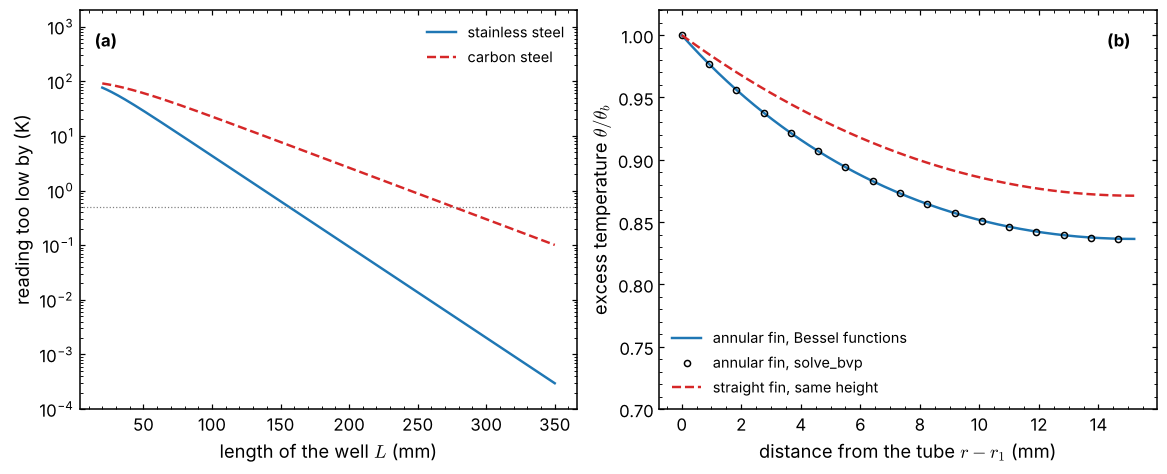

In [5]:
r1, r2, t_a, k_a, h_a = 0.0125, 0.0275, 0.4e-3, 200.0, 50.0
m_a = math.sqrt(2 * h_a / (k_a * t_a))
r2c = r2 + t_a / 2
den = i0(m_a * r1) * k1(m_a * r2c) + k0(m_a * r1) * i1(m_a * r2c)
eta_bessel = 2 * r1 / (m_a * (r2c**2 - r1**2)) * (k1(m_a * r1) * i1(m_a * r2c) - i1(m_a * r1) * k1(m_a * r2c)) / den
theta_bessel = lambda r: (i0(m_a * r) * k1(m_a * r2c) + k0(m_a * r) * i1(m_a * r2c)) / den

# the same problem by collocation: theta'' = m^2 theta - theta'/r
rr = np.linspace(r1, r2c, 50)
sol = solve_bvp(lambda r, y: np.vstack((y[1], m_a**2 * y[0] - y[1] / r)),
                lambda ya, yb: np.array([ya[0] - 1.0, yb[1]]),
                rr, np.vstack((np.ones_like(rr), np.zeros_like(rr))), tol=1e-8)
eta_bvp = -k_a * 2 * math.pi * r1 * t_a * sol.sol(r1)[1] / (h_a * 2 * math.pi * (r2c**2 - r1**2))
L_c = r2c - r1
eta_straight = math.tanh(m_a * L_c) / (m_a * L_c)
print(f"m = {m_a:.2f} 1/m, m (r2c - r1) = {m_a * L_c:.3f}")
print(f"efficiency: Bessel {eta_bessel:.5f}, solve_bvp {eta_bvp:.5f}, straight fin {eta_straight:.4f}")

r_plot = np.linspace(r1, r2c, 200)
x_plot = r_plot - r1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
lengths = np.linspace(0.02, 0.35, 200)
for name, k, style in (("stainless steel", 16.0, "C0"), ("carbon steel", 50.0, "C3--")):
    m = math.sqrt(h_g * P / (k * A_c))
    ax1.semilogy(lengths * 1e3, (T_gas - T_wall) / np.cosh(m * lengths), style, label=name)
ax1.axhline(0.5, color="0.5", lw=0.8, ls=":")
ax1.set_xlabel("length of the well $L$ (mm)")
ax1.set_ylabel("reading too low by (K)")
ax1.set_ylim(1e-4, 2e3)
ax1.legend(loc="upper right")
panel_label(ax1, "(a)")

ax2.plot(x_plot * 1e3, theta_bessel(r_plot), "C0", label="annular fin, Bessel functions")
ax2.plot(x_plot[::12] * 1e3, sol.sol(r_plot[::12])[0], "ko", ms=4, mfc="none", label="annular fin, solve_bvp")
ax2.plot(x_plot * 1e3, np.cosh(m_a * (L_c - x_plot)) / np.cosh(m_a * L_c), "C3--", label="straight fin, same height")
ax2.set_xlabel(r"distance from the tube $r - r_1$ (mm)")
ax2.set_ylabel(r"excess temperature $\theta/\theta_b$")
ax2.set_ylim(0.7, 1.02)
ax2.legend(loc="lower left")
panel_label(ax2, "(b)", x=0.9)
plt.show()

**Figure S3.1.** (a) Error of the thermometer well of Exercise 1 against its length, for
stainless and carbon steel; the dotted line is 0.5 K. (b) Temperature along the annular fin
of Exercise 4, from the Bessel-function solution and by collocation with `solve_bvp`,
compared with a straight fin of the same height.

The annular fin is 87.6 % efficient; `solve_bvp` agrees to five digits. A straight fin of
the same height would be 91.4 % efficient. The straight-fin formula is optimistic because,
in an annular fin, the area grows with radius: most of the area lies far from the tube,
where the fin is coldest, and the heat must spread outwards through a section that also
grows, which the straight fin does not need.